# Predicting Cellular Uptake

**Can a polymer recipe help us predict how well cells take up polymer–DNA particles?**

You’ll use real experimental data to build a simple prediction model. Along the way, you’ll explore the data, fill in missing values, choose useful inputs, and check how well the model works.

### Get started

1. Choose **File → Save a copy in Drive** to make your own editable copy.
2. Click **Connect**, then run the cells from top to bottom with **Shift + Enter**.
3. In each **Your turn** activity, change a dropdown or slider and run the cell again.

The data is included, so you don’t need to download a separate file. The activities let you explore different settings without changing the final model’s setup.


In [1]:
# 1. Tools for this lesson (normally already installed in Colab)
import io
import sys
import base64
import gzip
import hashlib
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

plt.rcParams.update({
    'figure.figsize': (9, 4), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.labelsize': 11, 'font.size': 10,
})
COLORS = ['#177E89', '#E6A23C', '#725AC1', '#CE5A67']
print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}', end='\n\n')
print('Ready. We use LinearRegression throughout.', end='\n\n')

Python 3.12.14 | scikit-learn 1.8.0

Ready. We use LinearRegression throughout.



In [2]:
#@title Load the dataset
SOURCE_COMMIT = "15e8e34a062f023cb1844fe5762d32f459bc1ef0"
SOURCE_URL = (
    "https://raw.githubusercontent.com/mbhaylett23/pBAE-cellular-uptake-ML/"
    + SOURCE_COMMIT + "/GeneDataforModel.csv"
)
EXPECTED_SHA256 = "32a75f180907b2981e7acd8d1764115a882df48329018dfa4fcdde4a18037b0a"
# Compressed, unchanged CSV snapshot, with CRLF converted to LF for verification.
EMBEDDED_CSV_GZIP_BASE64 = "H4sIAAAAAAACA+3d264ct5UG4Hs/C9UgF8+XsuQtGZFlQ1KMSe4CjC+MMTBGkhvP08+/SHazKOcBegE/nGzZW91VLHJ9rCoef/7HP4N7U97j/5/w/7+4N1He649P+gP/+ctvv3354/df3Odf/+8X99P//vbHf//6r99/+ee/fv33H+6vv//7H//zi3v95svHMH7K+BnHz+Rev/v0/Uf37duPL+7N65+D/hD9Ed2btym5Ny8f8J8/fkivg/5R7n+MX3b94/NLcN+9e/nkvvvyObiXdy/zR9OfRX90/fFJ3MuHj6/dy+c3SMbL39+Ke/fx9ff6810Q9/2H+sl9/+Xd6zh+5vGz6M9vw/g5/725H7774n74/NH98Lf3HT8+/MV9fPfiPv745c17mX9E9+PnHz65n96+e3njfvrw+q/u06fXn8cPcZ/fvknuy7sXHPXL+2+R3p+/04/9/P0P7u9/+69vghPvmnf3f378+c3rT8kFkVt2/uZLKy6Wm2Qnt+ab1BB790lyd6/yTbqPPaSSvK9S3atwEym++558jSkFHCHFFCXUEnKtPrhX/haliST8R/P4mHuVbjnmWGsKPYbWk34m+yAx1BZbzjiBe4WzhxYkt4APlxj1ax4fwcEltpp71rP7XFOrpfqC74/k4Mse30JqehM9Mk5dpOfsYwheEyQ3/TPgI1F/6V7FW5GGI2VNQJ8HbkgZUii4cN9FT16DtFx6Ty0n5BEOUyL+HemXlHGtehxclbQSCn4xrivd8G+le6QK2ZSLC7faewm146jItaJ5GmuqBdeILMqlaZJDibUhoysOVGrUI8cuvuOvkYBcA46DNOBfEi68S46anNx87Q3/HXH9TS8i40wZF1tLr7XrZ1ILvmQ9asLp9TMolNCLZnxoUZOTujSUeakhSxqHQXEGCfiJsk5dU1N9xBEKUpByKvqb5HOX0Fvt+L0GEsoXZ0UeltLnRxqOEAsuASnqZZZDbciLHjrOFWfxdSS1oUCljItKGb8SxBTyRzT/uq8ZuZuRNa3P5CGOvE+ti17GSIx+HJGDwJQ2ojRXEYRwQgknGcWJnCy1tF5w3DovqjUcFFfk8bGRN9GHGntETiEVGtv4jvc5pgIQUUMZZYXYbxEoapOSR8ThHA2XiiT2HJFGxCDKu/oekI8ibeRGQXYgwBCsOMm4DpRjiwm/i9LL0AYcGfYQeYighotHjhdEPxxF5KEmKFaIqYIgw5/yjbjkXfkPuova1quB60TapE3axmhHvWvLn2gj+MaNGwnQWzbv28RN3OZwJ+cP3o/7dphP5S1mV+GPuImbuI3hRs7rM3n6E26vtAHFIXgIm7AJ2xZsvFQfrWkLdmyzLS3k5pCvlE3ZlG1Ldp2ov34eR5yra5+Do2u6pmtrrttsHP/6UbxM14gGJ3zJpmzKNie7z5v118/iKAJ9yUYB6e2crumark25Dt4hd92f+71U+i0g2tksTtmUbVA2UnnYvreLe9FbNr6WXay3St3UTd3mdMswvX3fH8jz6tJG0lwR2qZt2rZmOy7T986ve/N4bWssWkXpoDyIm7iJ2xjutHDfR5LfcaeJ24t0lz2fy8mbvA3yzov3fbjp4p18n/fu2JwkjiOnbuo2qLs8WtOm73truYxbdxfctWtlgzlxE7c93PWBew4nvzeY1zhu3aW4Fmmbtmnbnu32sD0b1R6dYfisfh4Z1EibtEnbHO2+n8ivz+T4y9mg1gG7cFEG2qZtc+utXB7Ij0fyHMZiSihQXCxlUzZlG5Md9uP49YG8oUC0VGpE4SBLaJu2aduYbVm276PTHmspafJjSxlHYQ8YbdO2Pdvx0ZA2dd/v24ho7d7GubNw8ApxE7dB3OkyEUx5L9wVWYuP55C0e5u0SZu0rdHOe7WV65jyCpeaDtER5WxKI23SNke77AVXriPK0311U+SaS4EP5eRN3gZ5173jQDpGlMexdDGuK3Q2pxE3cRvE3faSStfpIggfxR2RqY22aZu2Ddrue4nT45V7dH4hIYCUMnVTN3Ub3C/ostDp9a1bZDyW41zBJY46JW3SNkc7uMcuf9c37lZvfbxyV5/dWGeJuqmbuo3plr2OsRzrIq4FWLL2g7FFjbzJ2yLveAwr32/dY1SaUhSui0japG2QdtqP5OW4c9c101NHsVTPB3PyJm97vPMx1XPzjot3RHA4jmIhbuK2h7scazTs5vI4aUvXKSS0Tdu0bc52Pbq59wi1HNcAVEQaZLNFjbzJ2x7vdvRz7xXLw8AdUHyczk3btG3Rdj86urftXtZuBH00lpM3eZO3Od7p7OnevFsbuKM4zgujbdq2aDsc3dyXx3K/msvBJBS2qVE3ddvTLUdP997f08+Xblxp4ua9xE3cFnHHo59745a5SRgeyzm8nLZp26LtdHRz747umkZXWEwucv8/4iZui7jzsS/3Xq4heMVdG5wHyqZsyrYmuxybcm/ZRWZrWo3FZW7/R93UbVB3vWzreW0rT7MfDJnnsidt0iZta7TbZTvu6+DTuqZzN184aYS2adug7b4XLb9uElb7rWmpBHWDcKFt2qZtW7az36uWjyfzvcjS2Nszddy0C3vBqJu6DeoOe9HyY+NenQeqM7lx/45chYW0SdscbdlLlo+X7jvtuWS5xgJskzZpk7Y12nEPW7m+b+d2y+N9W5/JW+IzOXVTtz3dyfljp7D7qNMyW9M8sLjKh3Lapm1ztvOeKXJ938a1r3nc+KxDCoibuInbGO6yJ3le37iljsY00Mq6vyefyombuM3hrtf1Gdp1O4IxE0xXNG6UTdmUbU12c+ceYV8tVy6xj2FrpE3apG2Ldr+uh3jp3pY5dgX5kzgPjLIp25rscixkfOndbnPgCvLOjTY14iZu4raFO1xmbus/P73++MYL7tprjidy3yWdNqIscVn4Vky+JeTFyBTEJiIVv+k9jmQKICAOYwww0rVOQJwikVpgFQX9atQSmsaiOSejXBHpsYE6MgCRpF9CKhHASDXSqYNoFByiI6eKj2nVkm4d2VpQ38BH8rrgMkIL+HMpWrWM6MB5gUujsLSkCzsiX3HMjkoqh6L50SQieS0ifnCkka2oqBCFCNOMQJu1DzIev/MxVnylNxxCKmoHnG6mH/5k5HNCSSQ9SEXRRK2cUK21cRCkVqogozxqmvktfAnZ0DKKrQUtv9KQe7V4ZEZM4yIL6k6trVAdpfGRNL4Sc+2px1lboqyRdFwZ8ldjBdGLEpfqcR690nFRKAakHwB9HJmFqgABmPQi8I8eB7WvLqLVUTqo/UaaEb44SYxaRRQZ2VU7joHARLUr40q7XioyKIJt1ZjT0kUVljRI+ojvjNxG1GsyITOPMOmoiFB/CcpsXGhDZCPZoBPmcZHfSF1VS6iTxm+y1spamwYUtUMFgSoyavpQDH3sMY0bBM4J3wG1uR9VdUdJt4CYxF2ljvjT1mHkr/caXFVTnFAv6mWDrRYo8kJrPdQSgrBtecRS0ZxJms0zthDgpWut3zTc9EuIYpAGtJhzkPkt3AvBP2i8javA7Q6AUXXiYrXg9DfwgKoEJYaaI+Z1V8KrcGu4D4LSJKJeYQ+1Omq+4Qxh2cE8oAbEL0AW4YgE4/5Wwzdymbh9wC5zsbSI21YqhE3YhG0KdrxM7LzAxuPiuGPjkSHPFYwJm7AJ2w7sdMzZvtyxw5q1rTsGBd6xCZuwTcHOxzorF9hzhbSikUzVVE3VllSXY9XDh+rYZssZonKOQKNruqZrO67rsVTxw3X2mk/BZ91jhKZpmqbtmG7H1gIP02WaRmJomqZp2pTpfuz0tU33samAhE7TNE3TpkwH74LfXVu7c0uVI/R0SA17tsiarG2x1nfmK+x7C7iXuQGQz7p1n1A2ZVO2KdkyPG/b96fwvDqta9JmcLqma7q25DrupRXatRV8bSGArNVZ2In9W6RN2rZop70kUrnSTmt3EMHJS+LTOGmTtjHaea9TKhfaoDLv2rHpUQibsAnbFOxy3fJHdru4jDs2COhmfXwYJ2zCtgW7Xvf7SbtlvMZxxy7FZaFruqZrW67bdTuQdunxAiYF1XCUTtZkTdaWWHd3WQxJLpM+8mw76y079naRNVmbWivl8gx+PIXnsXZhSc1VPoSTNVnbYh32I/j1IbwhYPRujfLK0E7ZlE3ZtmTLkn0fePZYBElv2AiwsZg4XdM1XZtyHR/NZlP2/Y6NfNT+awRKKVRN1VRtSXW6zOhS10t1xcF16SNkoUscSkrYhG0Mdj62xt6wkQJ9ANedulImbMImbFuwy7Er9h5Iel+LNOnqZomu6ZquLbmux47YlwHiI6PwLRfZfU3VVG1KdTu2wt6jUvpYXiGWqBz4FE7XdG3KdT92wT7azeZuuRGv12RN1mRtaQOfcwvsy2SukVHiQ3C1cp0zyqZsY7LDsQP27r6utz7er6vPTtNI13RN13Zcy7H/9WU211oyJSPAxoxNyqZsyjYkOx4DxPcrtujzt+5Er2uekTVZk7Ul1mk/g5fjhl3XPE0dmhK5PRdpk7Yx2vmYqblpx0U7Rh2Wxns2YRO2KdjlWFlhN4vHyRqnTlRN1VRtSnU9erD3iLMc10jSMnzzQZyyKduU7HZ0Yu91xMNwjfzhBnxETdS2UPej/3qj7mVtDtC1ROmarunakOt09l9v160N1UMVh4jTNV3bch2O3uvLQ7hfreG6Qx/HklI2ZRuTLUcH9t5Z08/X69p16ULesgmbsG3Bjkf39YYtc5MuqCpcWYGqqdqU6nT0Xe/e65rmFvfJJeHtmrAJ2xjsfOyDvRdXCH7sb98Sm8OJmqhtoS7HDtgbdZHZbIYCcxwdTtiEbQx2veyleW5uP9dWQF5w/jVVU7Up1e3Y1X4PIq1r/nXzxXE3TbIma1Os+14+/Lo/V+3IR93uA5nphKzJmqwNsc5+Lx4+HsX3KkhjO82EcuPdmqzJ2hbrsNcOPzbJ1YmbOu1a79lUTdVUbUm17LXDrzvah7l2ePDaYsYtAciarE2xjnskyvXVOrdbHq/W+gweOcyMrunalOvk/LE1133waJlNZjhn4Zb2lE3Z5mTnPdXj+notua+Z11Vwy26ETdiEbQl22bMzr2/YOOBYOhx54CIbzsiarE2xrtflFNp1T4AxiUu3vmbfNVVTtSnVzZ27c321cDiO7xIHhhM2YRuD3a9LFV56r2WOSWnRpULVVE3VhlSXY2nhS+91m2NSasa7deXtmrAJ2xTscJlwPW7YXwJu1WtyZkGYFF0+HJclyM7uEQ4AMAodOY7wgzyADTM3EqK4p9wRBDgtfCIHcQkoK1ytqkF4S0RhoFwQRlEP7GMJMWm9kGLRBFbEWtK4QMYjwxA53aM4Q8AhJDQN7lgANCLgESZwJLr6Wm4JwZZwpRqAGTVOQTCjHgg5arjhbxDIuDQoR1URQQYZohUIYqDreUJDUjyirVXg0ZgIWWsEXDdCCg8tAlU4WOgp1tpnD0GNsATD4gvkjHLKPuA4UI1Li6imlDkOkrQ6SFlrSi1wrRP0OBHihtiGbyGHERwt6+mRVz3pL5CFEdkxjiP4W9SBqF8FqhHr+JtSsmYxAhApDOCAklXVGm6oEZOPXXQ+HgJRNLNwcUCE0+U8jhEQvAIJel6Pgiy34IElIkilaKMqCh9X24JWC1H7PXGa3hsOii8iuPQgiGOEZ/CCkO5aNZeAK8yoILVeGrmJLyMmETK4IOWTblo5wR9iHucb9w5U3lqJZNQaMKwXBFuoCpGnyMOspwaKUBEhiLNWRxWgdSOyDckL4wIgHvVw0PoF5qoMzKiQahIN4z45Zfx9R2Bp5YoS1ozQiscX2MmIJV3ND/UKkq/1iLoctSg+ihoCZY4UiNYKETUHIkKrEhSW/kJwPciHiOwtcdSGCHcNPLgPaWQ5ChI0ei5aEQ0FWivimxl11dh8o2uR+RHliMlx4RWstFIFsKy2kf6I2hHVM26J8Ru5TLPelMtcxAypdEUImZAJ+dkhx8sEzDtkKXOd0YBCdomO6ZiOn91xOqZS32/IYc2kjrovJiETMiE/O+R8rHRyhzyXJYOszOdqMibjp2dcjuUFJ2MU4nyuzs3FruuGkjIpk/KTU67HEsCTcvaagIAsHmVEyIRMyM8OuR0r9E/IZULWxI8ddQiZkAn5ySH3Y3esBbmPNfmRh4RMyIRsAnLwDuHrvup+Ute3MAqajumYjp/fse5YeZU8Wq29zF1yvA4H4VsyLdOyBcsyBG/N4+k6r67kiggKjZIpmZKfXnLc6xO0R8v1Wl4/BJ36UCPvy9RMzRY0p72MUHloTmuzDBSxq5mYiZmYLWDOexVPuWNOfq4KFhCuwhdmWqZlE5bLdbsbWY3YMm7LCP6sO78TMiET8rNDrtcNbtJqxa5x3JRL4dhrOqZjC47bde+Ldu+NQvFpEeqiQJWQCZmQnx5yd5e1gOQ+iyLPJi/EsC6Rz9dkYiZmA0uGXJ6t99N1Hiv1FcRPEY72omRKNiA57Kfrx/N1Q5LHHIqo3cqcFEXMxGwCsyzM9wFfcwUgvS3HljQvOZmCkinZgOT4aPaalsdtGTGiXcqtuBrpmI7p+Okdp8uEKJWsjvWJWj3gElzh0zUt07IJy/nYsHlZ9jeNApE5AJuUSZmUn59yOfZoXkM270tsptxc5bwoSqbk55dcjz2Z74Ovx24dCFqXue4AJVOyBcnt2IR5DRAZHDQS2XhNyZRsQ3I/9l3ejV5zg9boMiETMiE//4Yy51bL99lQ4+FafNDWL0ImZEJ+esjh2Fp5dSfXWx+vyRVpa+xQpmRKfn7JcmynfJ8PtVYOAQ1XC1+UiZmYLWCOx9Dr9aI8GrqQbhGH7CNkQibkZ4ec9qN12XfluiY36uCQVNkRRczEbABzPqY2LsxxYUaIIjuJmZiJ2QLmciw6sJqw46SMa86djumYjp/ecT16lNc4rxzXiM2CHM68J9MyLRuw3I5O5bX6dRiSkTjHRi8yJuPnZ9yPLuXFuJe1iH0vwt0biZmYTWBOZ6/ywtzaoIyQD2RMxmT89IzD0Z98f7T2q+06IOg778nETMwWMMvRp7x2b/TzPbl2V7n0NR3T8fM7jkd38nIsc4MohHzlwtekTMomKKejM3l1J9c0N0dPeGMmZVImZQuU87Gf8lpvIPixM3pDyfPpmo7p+Pkdl2Mn5eV47EChkmNxkY3XlEzJzy+5XvZrvOyKPpcbQPKFL8q0TMsmLLdjS/Q1XrOuecoNORMSx2vSMi0bsNz3wtePPaJqvzW1jC8hNzM7lYmZmA1gzn4vfT2ftedSQGPvxtSVMbdGp2RKfn7JYS99vTdh1QmPOku5KWTelWmZli1Ylr349WN39DAXv0ZcI/0ctknLtGzCctzDQx6vy7nd8nhd1ifsWNmOTczEbAFzcv7YK2qM3Syz7ctrucXEOzMxE7MFzHnPpXi8MUvua8Zy1ZtyImVSJuWnp1z2HMfHC7PU0fiV8S0XubEyLdOyCcv1uvBAe6xpP2ZHFVBuHClCyZRsQHJz55ZR13WwBYHIl2VapmUblvuxRN+yLHOciG4XxR2j6JiOn95xOZbNvXcttzlMRMMuZr4p0zItG7AcLtOV9Z/3b19wS15THQtMZ6+W5Yak4HEbl478UZXlhrDyJRRcUUxqGZ9BlkdEkhbw6M4SBFlE+eJ7FdEzCgulhroi4ZM9KBB8r2Qkp+EDuTUdGn5rDfncYDHOogi3HIAAJYYo1hDVk+E8yDL1jGvEl6JWAnqxMcg8F/LFF5xbywaxoIWM+NN9ZpFLCOCqW8BXSEAxo5BD1N0rkT6vuPUbiHkNudICytKHDoptKOuorvTSCi5HRA+scRGBAwSQJ/oZYEKtgNL0en2qteM7yL9StAyq/kY/ErQiSlpHDkYaFyGiyFH2YeYzrgoZA/QxD2oIiIZ6A1WiF9FayGdUnfgIIsZr5aGVKOpLhACOpm4QPXqV4CZ4eZKxSycqRwRuSBXx0vPIU1SGgIYMiPp1fCujxgBRjbM5bQ4p8cCHc6HmGUWM8tbY0ppMahy0UMMmQd2aA9COu0LxKHUENy4KWTSvAbUCYEALuIzcEa0X9cQx91lzVdTpqF19UJmayz1o1eQr0ltmxwry3yPHmn5SyxzegRgJglkfR4WBew/84jComapeJo4ZUIHAROll3BxwX1KOqCK0YtPP4NSINsldlY0grShanB/n1u+ASEGFjgoQ1aaM6gxFFCoqEa0m9dSAj5Tj4wH1Q8vzfod6GYUekEeg3UdVhNTiVpZRtaLaGFGK+1j3qIYQtnncSfX5uEZ8R1MlTmvbgloSmYXvStTKFXde3D96RtVX6jdymb68XZe50FfUCRZjKCdd0zVdG3IdLxMg764RsuN+HXCNrpI1WZO1MdbpmNl8v12HNbdZt6JJdE3XdG3MdT5WH7m7niuCIfSS3riJmqiJ2hDqcizyN1HHNtvMQm58BKdqqjanuh6r8E7V+HuNb1y5i2wGJ2qiNoa6HavkT9Rlota+uULRFE3RlkT3YzOqJbqP5fLxAS1ZmqZpmrZkOniHjHNf9WopcXwSiaVoiqZoU6J118ir6dHw7WXuauOzy3z0JmqitoVaBuXNejx759VLXVGWjY1kdE3X1lzHvehBezR9r5X1Ef86YTpRNmVTtjXZaa9MVB6y09ozQxABubCzmrAJ2xrsvBcDlTvs5Oe6Y8h6J2wHp2qqNqa6XPfEkdUOLuNmjYzGY3gha7Ima2Os67E7zmoMr3HcrJHfOfMZnKzJ2hrrdt1eo937uEBaWbeoSyfQNV3TtTHX3V0WOJL7/I48G816yxxkRtZkbW5FlMsz+H4Kz2P1QSSGLWZETdTmUIf9BP54Bm9IkZZZjSVzijVd07U917Jc3webzXWO9GaNvMqcjUnVVG1PdXy0mE3X426NNGqEt6K74LHBjKzJ2hjrdJm6pbCVdQ23saZ2QNlmjguna7o25zofm04v1/6mk61Ft9ESsiZrsrbGuhzbT6+xo/fFRhHGLsVbJGzCJmxbsOuxFfV9UHgcawiH7jh4lKiJ2hrqdmxKvUaj9FUa0XFiJlVTtTnV/dieejeZzW1twboRNVETtam9ec6dqu/Tt8bztwLQAeG8V5M1WdtiHY5Nq1evdb2Nkm/VZ20vY781YRO2Mdhy7GJ9n8C1VkfJqqxTNVVTtSnV8RgQvl6tx263SBZCLVU2mdE1XVtznfYTeNl367qmZep4FPyarMmarC2xzsekzMU6LtYx6lE7X68pm7KtyS7HKgqrOTxO1/pm3dkaTtVUbUx1Pfqt1yCzHNfoUUQS9+uhaqo2prodHddrofBRYj7AGOdbUzVVm1Pdj37rpbqXtfx/VzFUTdVUbUl1Ojutl+rWhukoXJ2QqInaHOpw9FnfH8D9agYPwvUJyZqszbGWo8t6bZnp53t1xXs1SZM0SZsiHY/u6kVa5tZbePwWtpWRNVmbY52OvurVW13T3LE+OfyPpmmapi2Zzse21mvthODHdvUtsVeLqqnanupybGm9VBeZTWU1akhwvChd07Ux1/WyReZls/q5fMIQTdZkTdbGWLdjo/o1YLSuWdaAy3UJyZqszbHue3Hwx85btd8GS1x4dpy1Rdd0bc119nt18PEwvlY7Gvtkpg7SlaiJmqhNoQ57ZfC9961O0NQp1i1zcBlVU7U51bKXBn9sVB/m0uDIUdyqEx/B6ZqurbmOexTK49U6t1ser9b6CJ45GIWqqdqW6uT8sfHWGDdaZoMZSlR35eLtmrAJ2xrsvKd3PF6ucTVrlnWdK5gRNmETti3YZU/HfLxfSx2tZrmj5GLgAFK6pmtrrut19YT2WPd/zN8qypqmaZqmTZlu7tx967o6OCC7QNRETdS2UPfrkoT3bmuZQ1EavsBmcJqmaVOmy7F48L3Tus2hKDXjmJkv1XRN18Zc/z9y3lUNXJkDAA=="

try:
    with urlopen(SOURCE_URL, timeout=15) as response:
        data_bytes = response.read().replace(b"\r\n", b"\n")
    assert hashlib.sha256(data_bytes).hexdigest() == EXPECTED_SHA256
    data_origin = "Pinned GitHub CSV"
except Exception:
    data_bytes = gzip.decompress(base64.b64decode(EMBEDDED_CSV_GZIP_BASE64))
    data_origin = "Included, verified copy of the same GitHub CSV"

assert hashlib.sha256(data_bytes).hexdigest() == EXPECTED_SHA256
df_raw = pd.read_csv(io.BytesIO(data_bytes))
print(data_origin, end='\n\n')
print(f"Loaded {df_raw.shape[0]} rows and {df_raw.shape[1]} columns.", end='\n\n')
print("Source commit:", SOURCE_COMMIT[:12], end='\n\n')

Pinned GitHub CSV

Loaded 240 rows and 64 columns.

Source commit: 15e8e34a062f



## 1. Explore the data

Each row is **one polymer recipe tested in one cell type**. We have 60 recipes × 4 cell types = **240 rows**.

We want to predict **`Uptake` (%)**: the measured cellular uptake, not gene expression. [Dataset](https://github.com/mbhaylett23/pBAE-cellular-uptake-ML) · [Study](https://doi.org/10.1039/D3BM00741C)

| Column | Meaning |
|---|---|
| `C6H`, `C6R`, `C6K`, `C32H`, `C32R`, `C32K` | Mass percentage of each polymer component |
| `Size` | Size of the polymer–DNA particles, in nm |
| `Polydispersity` | How much those particle sizes vary |
| `CellType` | The cell type tested |
| `Uptake` | The percentage we want to predict |
| `Var1` | Row ID; not a model input |

The six recipe percentages add up to 100, so five tell us the sixth. We leave out `C32K` and use **7 numeric inputs**: five recipe percentages, size, and polydispersity.


In [3]:
composition_cols = ['C6H', 'C6R', 'C6K', 'C32H', 'C32R', 'C32K']
numeric_cols = ['C6H', 'C6R', 'C6K', 'C32H', 'C32R', 'Size', 'Polydispersity']
category_cols = ['CellType']
input_cols = numeric_cols + category_cols

display(df_raw[composition_cols + ['Size', 'Polydispersity', 'CellType', 'Uptake']].head())
print('Missing entries in the original CSV:', int(df_raw.isna().sum().sum()), end='\n\n')
print('Rows with missing targets:', int(df_raw['Uptake'].isna().sum()), end='\n\n')
print('Cell types:', ', '.join(sorted(df_raw['CellType'].unique())), end='\n\n')
print('Every composition sums to 100:', bool(df_raw[composition_cols].sum(axis=1).eq(100).all()), end='\n\n')

# A missing target is not a measurement. Never fill it with an average.
df = df_raw.dropna(subset=['Uptake']).copy()
X = df[input_cols].copy()
y = df['Uptake'].copy()

Missing entries in the original CSV: 0

Rows with missing targets: 0

Cell types: 4T1, HDF, OVCAR4, PANC02

Every composition sums to 100: True



,C6H,C6R,C6K,C32H,C32R,C32K,Size,Polydispersity,CellType,Uptake
0,20,80,0,0,0,0,122.5,0.068600,OVCAR4,36.25
1,40,60,0,0,0,0,126.0,0.017395,OVCAR4,24.00
2,80,20,0,0,0,0,260.5,0.111500,OVCAR4,2.25
3,0,80,20,0,0,0,121.5,0.083500,OVCAR4,74.50
4,0,60,40,0,0,0,120.0,0.076700,OVCAR4,71.00


### Keep training and testing separate

We split the data into three groups:

- **Training:** learn how to prepare the inputs and train the model.
- **Validation:** compare settings and choose a model.
- **Test:** check the chosen model once at the end.

All four rows from the same recipe stay together. This lets us test on recipes the model has not seen, using the same four cell types.


In [4]:
groups = pd.Series(
    pd.factorize(pd.MultiIndex.from_frame(df[composition_cols]))[0],
    index=df.index, name='formulation_group',
)
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
dev_idx, test_idx = next(outer.split(X, groups=groups))
inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_local, val_local = next(inner.split(X.iloc[dev_idx], groups=groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[train_local], dev_idx[val_local]

X_train, X_val, X_test = [X.iloc[i].copy() for i in (train_idx, val_idx, test_idx)]
y_train, y_val, y_test = [y.iloc[i].copy() for i in (train_idx, val_idx, test_idx)]
g_train, g_val, g_test = [groups.iloc[i].copy() for i in (train_idx, val_idx, test_idx)]

assert set(g_train).isdisjoint(g_val) and set(g_train).isdisjoint(g_test)
assert set(g_val).isdisjoint(g_test)
display(pd.DataFrame({
    'Split': ['Training', 'Validation', 'Test'],
    'Rows': [len(X_train), len(X_val), len(X_test)],
    'Formulations': [g_train.nunique(), g_val.nunique(), g_test.nunique()],
}))
print('No formulation crosses split boundaries. Test outcomes stay out of the activities.', end='\n\n')

No formulation crosses split boundaries. Test outcomes stay out of the activities.



,Split,Rows,Formulations
0,Training,144,36
1,Validation,48,12
2,Test,48,12


Discuss: do observations with similar input values always have similar uptake?



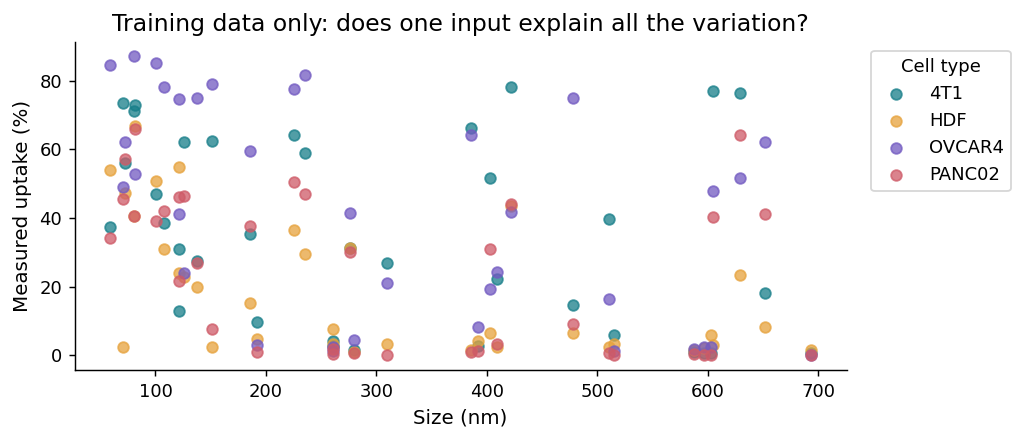

In [5]:
#@title Your turn 1: explore the training data
feature_to_plot = 'Size' #@param ["Size", "Polydispersity", "C6H", "C32H", "C6R"]

fig, ax = plt.subplots(figsize=(8, 3.5))
for color, cell in zip(COLORS, sorted(X_train['CellType'].unique())):
    rows = X_train['CellType'].eq(cell)
    ax.scatter(X_train.loc[rows, feature_to_plot], y_train.loc[rows],
               label=cell, color=color, alpha=0.75, s=35)
unit = ' (nm)' if feature_to_plot == 'Size' else (' (%)' if feature_to_plot in composition_cols else '')
ax.set(xlabel=feature_to_plot + unit, ylabel='Measured uptake (%)',
       title='Training data only: does one input explain all the variation?')
ax.legend(title='Cell type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
print('Discuss: do observations with similar input values always have similar uptake?', end='\n\n')

## 2. Fill in missing values

**The original data is complete.** We use a copy to practice working with missing measurements.

Try these example particle sizes:

`100, 140, missing, 180, 1000 nm`

Which does 1000 affect more: the **mean** (average) or the **median** (middle value)?


In [6]:
toy = pd.DataFrame({'Size': [100.0, 140.0, np.nan, 180.0, 1000.0]})
toy_result = toy.rename(columns={'Size': 'Original (nm)'}).copy()
for strategy in ['mean', 'median']:
    imputer = SimpleImputer(strategy=strategy)
    toy_result[f'{strategy} filled (nm)'] = imputer.fit_transform(toy).ravel()
display(toy_result)
print('Mean = 355 nm; median = 160 nm. These are illustrative values, not dataset summaries.', end='\n\n')

Mean = 355 nm; median = 160 nm. These are illustrative values, not dataset summaries.



,Original (nm),mean filled (nm),median filled (nm)
0,100.0,100.0,100.0
1,140.0,140.0,140.0
2,NaN,355.0,160.0
3,180.0,180.0,180.0
4,1000.0,1000.0,1000.0


### Hide some measurements

We’ll leave some size or polydispersity measurements blank, as if those results aren’t available yet. Then we’ll fill the gaps using the mean or median.

Each recipe appears in four rows, so we hide the same measurement in all four.


In [7]:
#@title Set up the plots and missing-value experiments
def mask_formulations(frame, group_ids, columns, fraction, seed):
    """Hide whole formulation measurements without using target values."""
    result = frame.copy()
    order = np.random.default_rng(seed).permutation(np.unique(group_ids))
    n_missing = int(round(fraction * len(order)))
    rows = group_ids.isin(order[:n_missing])
    result.loc[rows, list(columns)] = np.nan
    return result

def show_missingness(feature, percent, strategy):
    """A local exercise. Does not change the fixed modeling data below."""
    fraction = percent / 100
    train_demo = mask_formulations(X_train, g_train, [feature], fraction, seed=101)
    val_demo = mask_formulations(X_val, g_val, [feature], fraction, seed=202)
    imputer = SimpleImputer(strategy=strategy)
    train_filled = imputer.fit_transform(train_demo[[feature]])
    val_filled = imputer.transform(val_demo[[feature]])

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    cols = ['Size', 'Polydispersity']
    audit = pd.DataFrame({
        'Original training data': X_train[cols].isna().mean() * 100,
        'Classroom copy': train_demo[cols].isna().mean() * 100,
    })
    audit.plot.barh(ax=axes[0], color=['#A8B8C5', '#E6A23C'])
    axes[0].set(xlabel='Missing rows (%)', xlim=(0, 55), title='Which measurements did we hide?')
    axes[0].legend(loc='lower right', fontsize=8)

    # One point per formulation, because its measurement repeats across cell types.
    unique_rows = ~g_train.duplicated()
    before = X_train.loc[unique_rows, feature]
    incomplete = train_demo.loc[unique_rows, feature]
    filled = pd.Series(train_filled.ravel(), index=X_train.index).loc[unique_rows]
    hidden = incomplete.isna()
    positions = np.arange(len(before))
    axes[1].scatter(positions[~hidden], before[~hidden], color=COLORS[0], label='Observed', s=25)
    axes[1].scatter(positions[hidden], before[hidden], facecolors='none', edgecolors='#677689',
                    label='Original value hidden for class', s=65)
    axes[1].scatter(positions[hidden], filled[hidden], marker='x', color=COLORS[1],
                    label='Filled value', s=55)
    axes[1].axhline(imputer.statistics_[0], color=COLORS[1], alpha=0.5, linestyle='--')
    axes[1].set(xlabel='Training formulation (display order)', ylabel=feature,
                title=f'{strategy.title()} filling uses one training statistic')
    axes[1].legend(fontsize=7.5)
    plt.tight_layout()
    plt.show()

    rows = train_demo[feature].isna()
    example = pd.DataFrame({
        'Original': X_train[feature], 'Simulated incomplete': train_demo[feature],
        'Filled from training': train_filled.ravel(),
    }).loc[rows]
    display(example.loc[~g_train.loc[rows].duplicated()].head(4))
    print(f'Training {strategy}: {imputer.statistics_[0]:.4f}', end='\n\n')
    print(f'Actual missing rates: train {rows.mean():.1%}, validation {val_demo[feature].isna().mean():.1%}.', end='\n\n')
    print(f'Validation uses transform(), so it reuses {imputer.statistics_[0]:.4f}.', end='\n\n')
    print('Filling supplies a usable input; it does not recover each hidden measurement.', end='\n\n')

def show_feature_choice(k):
    """Show training-only relevance scores and held-out validation comparisons."""
    k = int(k)
    fitted = fitted_candidates[k]
    numeric = fitted.named_steps['preprocess'].named_transformers_['numeric']
    selector = numeric.named_steps['select']
    names = numeric[:-1].get_feature_names_out(numeric_cols)
    ranking = pd.DataFrame({
        'Input': names, 'F score': selector.scores_, 'Selected': selector.get_support(),
    }).sort_values('F score', ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].barh(ranking['Input'], ranking['F score'],
                 color=np.where(ranking['Selected'], COLORS[0], '#CFD8DF'))
    axes[0].set(xlabel='Training F score (individual linear association)',
                title=f'Top {k} numeric inputs shown in teal')
    axes[1].plot(validation_results['Numeric inputs kept'], validation_results['Validation MAE'],
                 color=COLORS[0], marker='o', markersize=7)
    selected_score = validation_results.set_index('Numeric inputs kept').loc[k, 'Validation MAE']
    axes[1].scatter([k], [selected_score], color=COLORS[1], s=120, zorder=5)
    axes[1].axhline(validation_reference_mae, color='#7F8A94', linestyle='--', label='Training-mean reference')
    axes[1].set(xlabel='Number of numeric inputs kept', ylabel='Validation MAE (percentage points)',
                xticks=[2, 4, 7], title='Same linear regression, different inputs')
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    chosen = names[selector.get_support()].tolist()
    print('Numeric inputs selected:', ', '.join(chosen), end='\n\n')
    print(f'Cell-type indicators are also included. Validation MAE = {selected_score:.2f} percentage points.', end='\n\n')

def run_missing_input_experiment(percent):
    """Fixed fitted model; only validation inputs change. Paired masks across columns."""
    measured_cols = ['Size', 'Polydispersity', 'CellType']
    rates = sorted(set([0, 25, 50, 75, int(percent)]))
    clean_mae = mean_absolute_error(y_val, complete_model.predict(X_val))
    rows = []
    for rate in rates:
        for repeat in range(10):
            for feature in measured_cols:
                corrupted = mask_formulations(X_val, g_val, [feature], rate / 100, seed=500 + repeat)
                mae = mean_absolute_error(y_val, complete_model.predict(corrupted))
                rows.append({'Missing input': feature, 'Requested missing (%)': rate,
                             'Repeat': repeat, 'Validation MAE': mae, 'Change in MAE': mae - clean_mae})
    measurements = pd.DataFrame(rows)
    summary = measurements.groupby(['Missing input', 'Requested missing (%)']).agg(
        mean_mae=('Validation MAE', 'mean'), mean_change=('Change in MAE', 'mean'),
        sd_change=('Change in MAE', 'std'),
    ).reset_index()
    selected = summary.loc[summary['Requested missing (%)'].eq(percent)].set_index('Missing input').reindex(measured_cols)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for feature, color in zip(measured_cols, COLORS):
        part = summary[summary['Missing input'].eq(feature)]
        axes[0].plot(part['Requested missing (%)'], part['mean_mae'], marker='o', color=color, label=feature)
    axes[0].axhline(clean_mae, color='#7F8A94', linestyle='--', label='Complete validation inputs')
    axes[0].set(xlabel='Requested missing formulation groups (%)',
                ylabel='Validation MAE (percentage points)', title='Hide one input; keep the fitted model fixed')
    axes[0].legend(fontsize=8)
    axes[1].barh(selected.index, selected['mean_change'], xerr=selected['sd_change'],
                 color=COLORS[:3], capsize=4)
    axes[1].axvline(0, color='#657381', linewidth=1)
    axes[1].set(xlabel='Change in MAE (percentage points)', title=f'At {percent}% requested missingness')
    plt.tight_layout()
    plt.show()
    table = selected[['mean_change', 'sd_change']].rename(columns={
        'mean_change': 'Mean change in MAE (pp)', 'sd_change': 'SD across 10 masks (pp)',
    })
    display(table.round(4))
    realized = round(percent / 100 * g_val.nunique()) / g_val.nunique()
    print(f'Complete-input validation MAE: {clean_mae:.3f} pp. Actual masked groups at the chosen setting: {realized:.1%}.', end='\n\n')
    mode = complete_model.named_steps['preprocess'].named_transformers_['category'].named_steps['impute'].statistics_[0]
    print(f'Missing cell-type names use the training most-frequent value: {mode}.', end='\n\n')
    print('The four cell-type frequencies tie here; this is a simple tie-broken baseline, not recovered identity.', end='\n\n')
    return measurements, table

print('Simulation and plotting helpers loaded. All simulations keep a copy of the original data.', end='\n\n')

Simulation and plotting helpers loaded. All simulations keep a copy of the original data.



Training median: 260.5000

Actual missing rates: train 25.0%, validation 25.0%.

Validation uses transform(), so it reuses 260.5000.

Filling supplies a usable input; it does not recover each hidden measurement.



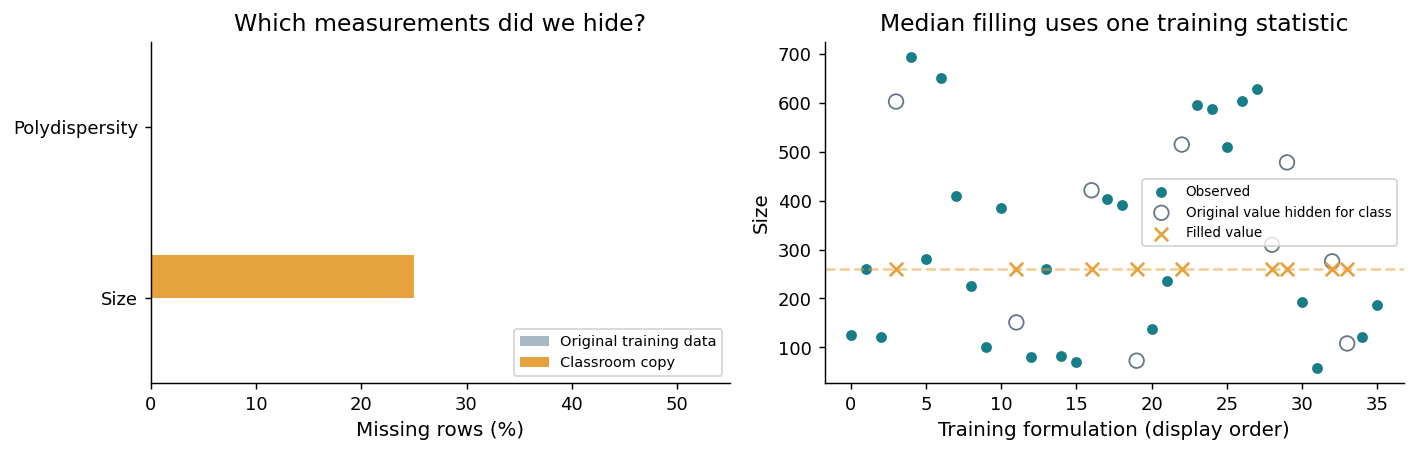

,Original,Simulated incomplete,Filled from training
7,603.00,NaN,260.5
19,151.00,NaN,260.5
25,421.50,NaN,260.5
32,72.75,NaN,260.5


In [8]:
#@title Your turn 2: compare ways to fill missing values
measurement = 'Size' #@param ["Size", "Polydispersity"]
missing_percent = 25 #@param {"type":"slider", "min":0, "max":50, "step":5}
fill_strategy = 'median' #@param ["median", "mean"]

show_missingness(measurement, missing_percent, fill_strategy)

**Try it:** hide 25% of the size values and compare `mean` with `median`. Then try 50%.

All missing values get the same replacement, so the filled points form a horizontal line.

### Set up the prediction task

For the model below, we use a separate copy with **about 20% of size and polydispersity values missing**. We fill them using the training medians.

The settings you tried above do not change this copy.


In [9]:
def classroom_copy(frame, group_ids, seed):
    copied = mask_formulations(frame, group_ids, ['Size'], 0.20, seed)
    return mask_formulations(copied, group_ids, ['Polydispersity'], 0.20, seed + 1)

X_train_demo = classroom_copy(X_train, g_train, seed=301)
X_val_demo = classroom_copy(X_val, g_val, seed=401)

numeric_imputer = SimpleImputer(strategy='median')
X_train_filled = pd.DataFrame(
    numeric_imputer.fit_transform(X_train_demo[numeric_cols]),
    index=X_train_demo.index, columns=numeric_cols,
)
X_val_filled = pd.DataFrame(
    numeric_imputer.transform(X_val_demo[numeric_cols]),
    index=X_val_demo.index, columns=numeric_cols,
)
display(pd.DataFrame({
    'Training missing (%)': X_train_demo[numeric_cols].isna().mean() * 100,
    'Training median used for filling': numeric_imputer.statistics_,
}).round(3))
print('NaNs after filling:', int(X_train_filled.isna().sum().sum()), end='\n\n')

NaNs after filling: 0



,Training missing (%),Training median used for filling
C6H,0.000,0.000
C6R,0.000,0.000
C6K,0.000,0.000
C32H,0.000,0.000
C32R,0.000,0.000
Size,19.444,280.000
Polydispersity,19.444,0.081


## 3. Prepare the inputs

### Put numbers on a similar scale

Size and recipe percentages use different units. We use `StandardScaler` to put them on a similar scale.

It uses the training average and standard deviation to scale both training and validation inputs. This changes the units; it does not automatically make our linear regression more accurate.


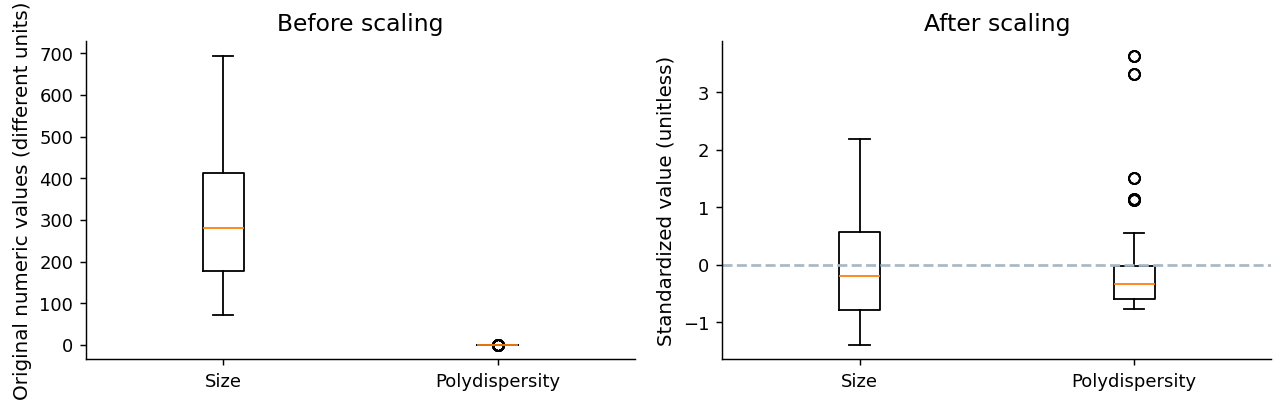

,Mean after scaling,Population SD after scaling
Size,0.0,1.0
Polydispersity,-0.0,1.0


In [10]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_filled), columns=numeric_cols, index=X_train_filled.index,
)
X_val_scaled = scaler.transform(X_val_filled)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
shown = ['Size', 'Polydispersity']
axes[0].boxplot([X_train_filled[c] for c in shown])
axes[0].set_xticks([1, 2], shown)
axes[0].set(title='Before scaling', ylabel='Original numeric values (different units)')
axes[1].boxplot([X_train_scaled[c] for c in shown])
axes[1].set_xticks([1, 2], shown)
axes[1].set(title='After scaling', ylabel='Standardized value (unitless)')
axes[1].axhline(0, color='#A8B8C5', linestyle='--')
plt.tight_layout()
plt.show()
display(pd.DataFrame({
    'Mean after scaling': X_train_scaled[shown].mean(),
    'Population SD after scaling': X_train_scaled[shown].std(ddof=0),
}).round(3))

### Turn cell-type names into numbers

We use `OneHotEncoder` to turn cell-type names into **0/1 columns**.

Three columns represent the four cell types; all zeros means the reference type. We keep these columns in every model, even when we change the number of numeric inputs.


In [11]:
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_demo[category_cols])
cell_examples = X_train_demo[category_cols].drop_duplicates().sort_values('CellType')
encoded = pd.DataFrame(
    encoder.transform(cell_examples), columns=encoder.get_feature_names_out(category_cols),
    index=cell_examples['CellType'],
)
display(encoded)
print('Reference category:', encoder.categories_[0][0], end='\n\n')
print('All four categories occur in each split. We are not testing new cell types.', end='\n\n')

Reference category: 4T1

All four categories occur in each split. We are not testing new cell types.



,CellType_HDF,CellType_OVCAR4,CellType_PANC02
CellType,,,
4T1,0.0,0.0,0.0
HDF,1.0,0.0,0.0
OVCAR4,0.0,1.0,0.0
PANC02,0.0,0.0,1.0


## 4. Choose inputs and build a model

A **feature** is an input to the model. We’ll compare different numbers of inputs.

### Remove a column that never changes

A column that is always the same cannot help distinguish samples.

We add a demo column filled with **1**, then use `VarianceThreshold` to remove it. Our seven real inputs all vary, so they stay.


In [12]:
temporary = X_train_filled.assign(constant_demo=1.0)
constant_filter = VarianceThreshold(threshold=0.0)
constant_filter.fit(temporary)
print('Removed in the temporary example:', temporary.columns[~constant_filter.get_support()].tolist(), end='\n\n')
print('Removed among the actual numeric inputs:',
      [c for c in temporary.columns[~constant_filter.get_support()] if c != 'constant_demo'], end='\n\n')

Removed in the temporary example: ['constant_demo']

Removed among the actual numeric inputs: []



### Choose features with `SelectKBest`

We rank each numeric input by its individual linear relationship with uptake in the training data. We then compare the top **2, 4, or all 7 inputs**, always keeping cell type.

A high score does not prove biological importance.

### Connect the steps with a `Pipeline`

The pipeline prepares the inputs and trains **linear regression**:

- Numeric inputs: fill gaps → remove constant columns → scale → select features.
- Cell type: fill gaps → turn names into 0/1 columns.

Linear regression combines these inputs using weights learned from the training data to predict uptake.


In [13]:
def make_model(k='all', strategy='median'):
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy=strategy)),
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scale', StandardScaler()),
        ('select', SelectKBest(score_func=f_regression, k=k)),
    ])
    category = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ('numeric', numeric, numeric_cols),
        ('category', category, category_cols),
    ])
    return Pipeline([
        ('preprocess', preprocessing),
        ('regression', LinearRegression()),
    ])

print('Pipeline defined. Calling fit() will learn every step from the supplied training rows.', end='\n\n')

Pipeline defined. Calling fit() will learn every step from the supplied training rows.



### Measure prediction error

**MAE** is the average size of the prediction errors. Predicting 35% when the measured uptake is 40% gives an error of **5 percentage points**.

**Lower is better.** We compare the model with simply predicting the training average for every row.


In [14]:
fitted_candidates = {}
rows = []
for k in [2, 4, 7]:
    candidate = make_model(k=k)
    candidate.fit(X_train_demo, y_train)
    prediction = candidate.predict(X_val_demo)
    fitted_candidates[k] = candidate
    rows.append({'Numeric inputs kept': k,
                 'Training MAE': mean_absolute_error(y_train, candidate.predict(X_train_demo)),
                 'Validation MAE': mean_absolute_error(y_val, prediction)})

validation_results = pd.DataFrame(rows)
validation_reference_mae = mean_absolute_error(y_val, np.full(len(y_val), y_train.mean()))
display(validation_results.round(3))
print(f'Training-mean reference validation MAE: {validation_reference_mae:.3f} percentage points', end='\n\n')

Training-mean reference validation MAE: 23.987 percentage points



,Numeric inputs kept,Training MAE,Validation MAE
0,2,16.012,13.884
1,4,14.875,14.845
2,7,13.610,12.678


Numeric inputs selected: C6H, C32R, Size, Polydispersity

Cell-type indicators are also included. Validation MAE = 14.85 percentage points.



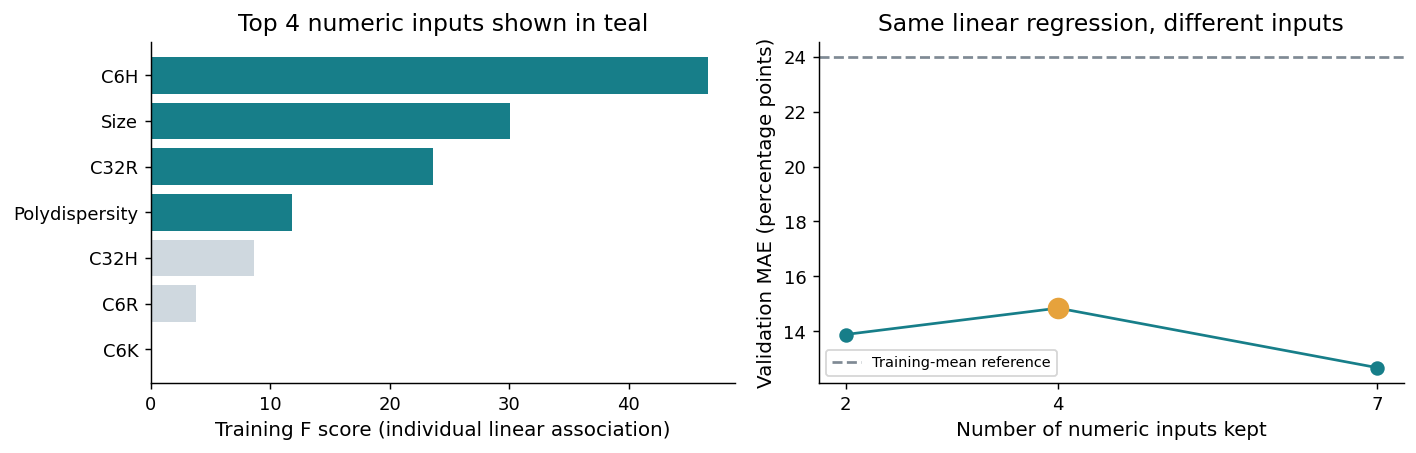

In [15]:
#@title Your turn 3: compare feature sets
numeric_features_to_keep = '4' #@param ["2", "4", "7"]

show_feature_choice(int(numeric_features_to_keep))

**Compare the results:**

The left plot shows which inputs we selected. The right plot shows validation error: **lower is better**.

We choose the number of inputs with the lowest validation MAE. Fewer inputs do not always mean better predictions.


## 5. What happens when an input is missing?

We keep the trained model fixed and hide some values in the **validation data only**.

We try **size**, **polydispersity**, and **cell type** one at a time. We fill the gaps using rules learned from training data and check how much **validation MAE** changes.

- **Above zero:** more error.
- **Near zero:** little change.
- **Below zero:** less error in this comparison.

We repeat this 10 times. Bars show the average change; error bars show how much the trials vary.


In [16]:
# Fit once. The next activity changes validation inputs, never this fitted model.
complete_model = make_model(k='all', strategy='median')
complete_model.fit(X_train, y_train)
print('Sensitivity model fitted on complete training inputs. No test data are used.', end='\n\n')

Sensitivity model fitted on complete training inputs. No test data are used.



Complete-input validation MAE: 12.554 pp. Actual masked groups at the chosen setting: 50.0%.

Missing cell-type names use the training most-frequent value: 4T1.

The four cell-type frequencies tie here; this is a simple tie-broken baseline, not recovered identity.



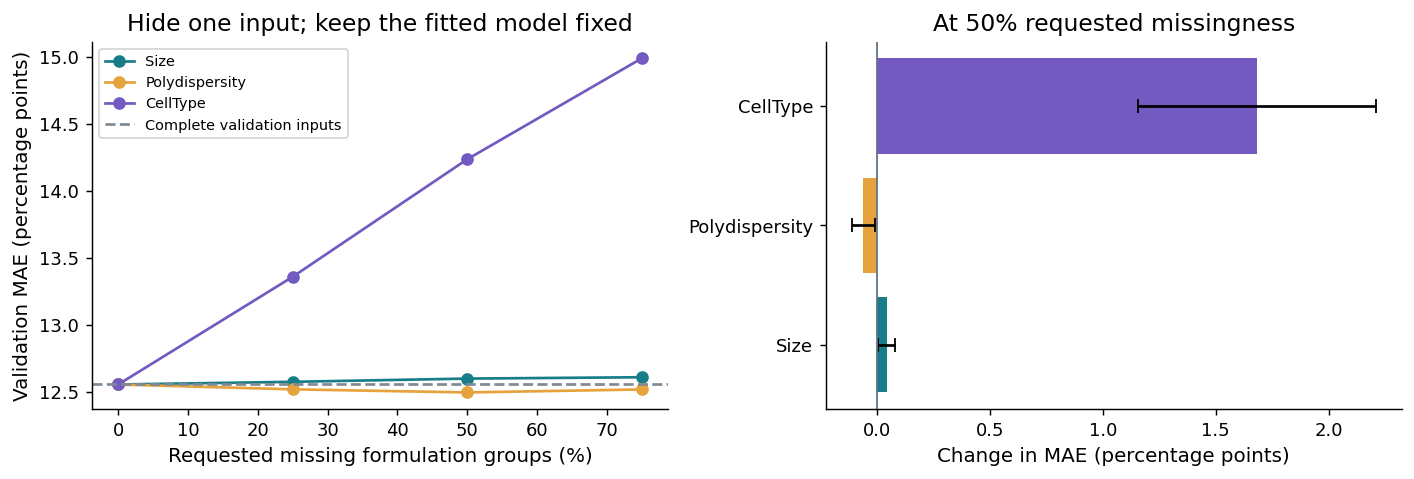

,Mean change in MAE (pp),SD across 10 masks (pp)
Missing input,,
Size,0.0441,0.0371
Polydispersity,-0.0592,0.0508
CellType,1.6815,0.5260


In [17]:
#@title Your turn 4: explore the effect of missing inputs
stress_missing_percent = 50 #@param {"type":"slider", "min":0, "max":75, "step":25}

stress_measurements, stress_summary = run_missing_input_experiment(stress_missing_percent)

**Discuss the plot:**

Which missing input increased the error most?

This shows how our model reacts to missing information. It does not prove which input matters most biologically, or predict what will happen in every new experiment.


## 6. Check the final model

We use the settings chosen with validation data and train again on **training + validation data**.

Then we test on recipes the model has not seen, using the same setup with **about 20% of size and polydispersity values missing**.

**Check the test result once, after choosing the settings.** These are results from this exercise, not the paper’s reported results.


Chosen with validation: 7 numeric inputs, plus cell-type indicators.

Test MAE: 15.178 percentage points

Development-mean reference test MAE: 21.926 percentage points

These are results from this classroom protocol, not reported paper results.

Linear regression can predict below 0% or above 100%; predictions are not clipped.



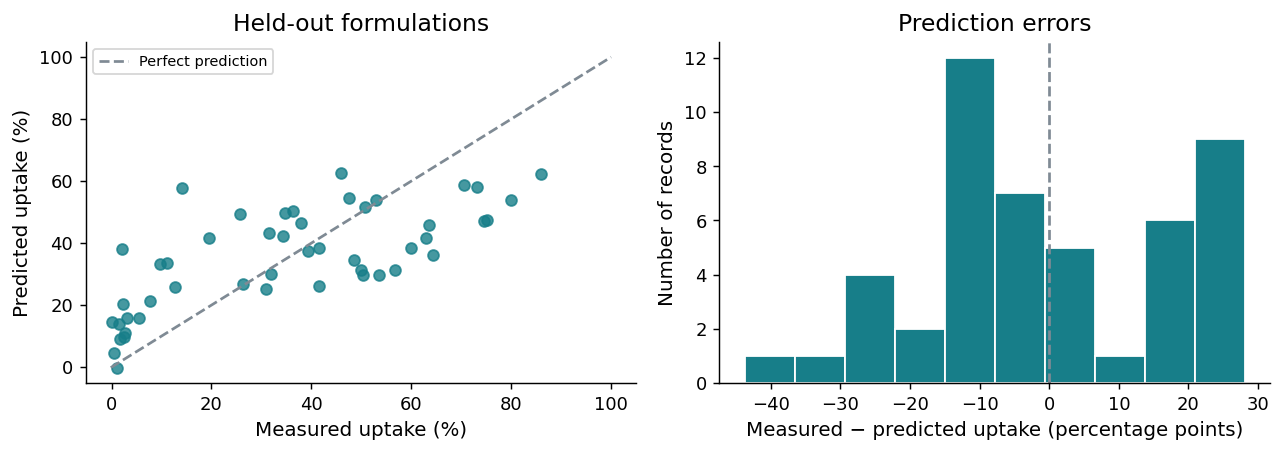

In [18]:
best_k = int(validation_results.sort_values(['Validation MAE', 'Numeric inputs kept']).iloc[0]['Numeric inputs kept'])
X_development_demo = pd.concat([X_train_demo, X_val_demo])
y_development = pd.concat([y_train, y_val])
final_model = make_model(k=best_k, strategy='median')
final_model.fit(X_development_demo, y_development)

X_test_demo = classroom_copy(X_test, g_test, seed=601)
test_prediction = final_model.predict(X_test_demo)
test_mae = mean_absolute_error(y_test, test_prediction)
test_reference_mae = mean_absolute_error(y_test, np.full(len(y_test), y_development.mean()))
print(f'Chosen with validation: {best_k} numeric inputs, plus cell-type indicators.', end='\n\n')
print(f'Test MAE: {test_mae:.3f} percentage points', end='\n\n')
print(f'Development-mean reference test MAE: {test_reference_mae:.3f} percentage points', end='\n\n')
print("These are results from this classroom protocol, not reported paper results.", end='\n\n')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(y_test, test_prediction, c=COLORS[0], alpha=0.8)
lower = min(0, float(np.min(test_prediction)), float(y_test.min()))
upper = max(100, float(np.max(test_prediction)), float(y_test.max()))
axes[0].plot([lower, upper], [lower, upper], '--', color='#7F8A94', label='Perfect prediction')
axes[0].set(xlabel='Measured uptake (%)', ylabel='Predicted uptake (%)', title='Held-out formulations')
axes[0].legend(fontsize=8)
axes[1].hist(y_test - test_prediction, bins=10, color=COLORS[0], edgecolor='white')
axes[1].axvline(0, color='#7F8A94', linestyle='--')
axes[1].set(xlabel='Measured − predicted uptake (percentage points)', ylabel='Number of records',
            title='Prediction errors')
plt.tight_layout()
plt.show()
print('Linear regression can predict below 0% or above 100%; predictions are not clipped.', end='\n\n')

### What did you learn?

- How did we fill in missing measurements?
- What does scaling change, and what does feature selection choose?
- Which missing input affected our model most?

We tested one dataset and one split. Results may differ with new cell types or experiments.


## Sources

- **Study:** Loecher, A., Bruyns-Haylett, M., Ballester, P. J., Borros, S., & Oliva, N. (2023). *A machine learning approach to predict cellular uptake of pBAE polyplexes.* [Biomaterials Science, 11, 5797–5808](https://doi.org/10.1039/D3BM00741C).
- **Data:** [pBAE cellular uptake dataset](https://github.com/mbhaylett23/pBAE-cellular-uptake-ML). The data and study belong to the original authors. This notebook adapts them for learning and includes a copy of the data.
- **Workshop slides:** [Introduction to Machine Learning for Biomaterials](https://ruiyum.github.io/nexabio-site/workshops/NEXABio_ML_Concepts_and_Pipeline_Feature_Selection.pptx).
- **Learn more:** scikit-learn guides to [preparing data](https://scikit-learn.org/stable/modules/preprocessing.html), [filling missing values](https://scikit-learn.org/stable/modules/impute.html), and [selecting features](https://scikit-learn.org/stable/modules/feature_selection.html).

The code uses fixed random seeds so you can repeat the comparisons. Small differences may occur with different library versions.
